# Week 2 — Baseline Model: Logistic Regression
**Goal:** Train a Logistic Regression baseline, evaluate with F1 + ROC-AUC, export to ONNX.

In [5]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import pickle
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, roc_auc_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

from src.features import get_splits, get_preprocessor_pipeline, apply_smote

## 1. Load Data & Preprocess

In [6]:
X_train, X_test, y_train, y_test = get_splits(path='../data/processed/telco_churn_cleaned.csv')
print(f'Train: {X_train.shape} | Test: {X_test.shape}')
print(f'Churn rate — Train: {y_train.mean():.2%} | Test: {y_test.mean():.2%}')

Train: (5634, 22) | Test: (1409, 22)
Churn rate — Train: 26.54% | Test: 26.54%


In [7]:
preprocessor = get_preprocessor_pipeline()
X_train_t = preprocessor.fit_transform(X_train)
X_test_t  = preprocessor.transform(X_test)
print(f'Transformed shape — Train: {X_train_t.shape} | Test: {X_test_t.shape}')

Transformed shape — Train: (5634, 45) | Test: (1409, 45)


## 2. Model A — Logistic Regression with class_weight='balanced'

In [8]:
lr_cw = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_cw.fit(X_train_t, y_train)

y_pred_cw  = lr_cw.predict(X_test_t)
y_prob_cw  = lr_cw.predict_proba(X_test_t)[:, 1]

f1_cw  = f1_score(y_test, y_pred_cw)
auc_cw = roc_auc_score(y_test, y_prob_cw)
print(f'[class_weight] F1: {f1_cw:.4f} | ROC-AUC: {auc_cw:.4f}')
print(classification_report(y_test, y_pred_cw, target_names=['No Churn', 'Churn']))

[class_weight] F1: 0.6184 | ROC-AUC: 0.8466
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



C:\Users\Swast\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 3. Model B — Logistic Regression with SMOTE

In [9]:
X_train_sm, y_train_sm = apply_smote(X_train_t, y_train)
print(f'After SMOTE — Train size: {X_train_sm.shape[0]} | Churn rate: {y_train_sm.mean():.2%}')

lr_sm = LogisticRegression(max_iter=1000, random_state=42)
lr_sm.fit(X_train_sm, y_train_sm)

y_pred_sm  = lr_sm.predict(X_test_t)
y_prob_sm  = lr_sm.predict_proba(X_test_t)[:, 1]

f1_sm  = f1_score(y_test, y_pred_sm)
auc_sm = roc_auc_score(y_test, y_prob_sm)
print(f'[SMOTE]        F1: {f1_sm:.4f} | ROC-AUC: {auc_sm:.4f}')
print(classification_report(y_test, y_pred_sm, target_names=['No Churn', 'Churn']))

C:\Users\Swast\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Swast\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Swast\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Swast\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1036

After SMOTE — Train size: 8278 | Churn rate: 50.00%
[SMOTE]        F1: 0.6180 | ROC-AUC: 0.8443
              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



C:\Users\Swast\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 4. Benchmark Table

In [10]:
results = pd.DataFrame({
    'Model':   ['LR class_weight=balanced', 'LR + SMOTE'],
    'F1':      [round(f1_cw, 4),  round(f1_sm, 4)],
    'ROC-AUC': [round(auc_cw, 4), round(auc_sm, 4)]
})
print(results.to_string(index=False))

                   Model     F1  ROC-AUC
LR class_weight=balanced 0.6184   0.8466
              LR + SMOTE 0.6180   0.8443


## 5. Confusion Matrices

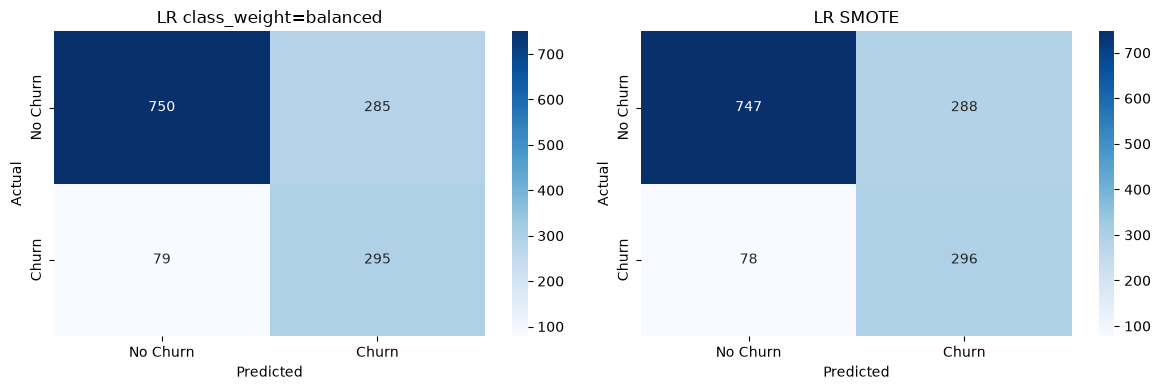

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, y_pred, title in zip(
    axes,
    [y_pred_cw, y_pred_sm],
    ['class_weight=balanced', 'SMOTE']
):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No Churn', 'Churn'],
                yticklabels=['No Churn', 'Churn'])
    ax.set_title(f'LR {title}')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.tight_layout()
plt.savefig('../reports/baseline_confusion_matrices.png', dpi=150)
plt.show()

## 6. Save Best Model as .pkl

In [12]:
# Pick the model with higher ROC-AUC as the best
best_model = lr_cw if auc_cw >= auc_sm else lr_sm
best_label = 'class_weight' if auc_cw >= auc_sm else 'SMOTE'
print(f'Best model: LR {best_label}')

with open('../models/churn_model.pkl', 'wb') as f:
    pickle.dump({'model': best_model, 'preprocessor': preprocessor}, f)

print('Saved → models/churn_model.pkl')

Best model: LR class_weight
Saved → models/churn_model.pkl


## 7. Export to ONNX

In [13]:
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import onnxruntime as rt

n_features = X_train_t.shape[1]
initial_type = [('float_input', FloatTensorType([None, n_features]))]

onnx_model = convert_sklearn(best_model, initial_types=initial_type)

with open('../models/churn_model.onnx', 'wb') as f:
    f.write(onnx_model.SerializeToString())

print('Saved → models/churn_model.onnx')

Saved → models/churn_model.onnx


## 8. Verify ONNX Inference

In [14]:
sess = rt.InferenceSession('../models/churn_model.onnx')
input_name  = sess.get_inputs()[0].name
label_name  = sess.get_outputs()[0].name

onnx_preds = sess.run([label_name], {input_name: X_test_t.astype(np.float32)})[0]
onnx_f1    = f1_score(y_test, onnx_preds)
print(f'ONNX inference F1: {onnx_f1:.4f} (should match sklearn F1: {round(f1_cw if auc_cw >= auc_sm else f1_sm, 4)})')

ONNX inference F1: 0.6184 (should match sklearn F1: 0.6184)
